# BAB 11 - PEMBELAJARAN MENDALAM (DEEP LEARNING 1)
## Praktikum 11.1: Klasifikasi Citra Menggunakan CNN (Citra Mobil dan Motor)

**Capaian Pembelajaran:**
1. Memahami arsitektur Convolutional Neural Network (CNN) untuk data citra spasial.
2. Melakukan data loading dan splitting data training & validasi menggunakan `ImageDataGenerator`.
3. Membangun model CNN menggunakan layer Conv2D, MaxPooling2D, Flatten, Dense, dan Dropout.
4. Melatih model dengan optimizer Adam dan Binary Crossentropy.
5. Mengevaluasi performa model dengan kurva Loss/Accuracy, Confusion Matrix, dan Classification Report.

In [1]:
# ==========================================================
# SETUP GOOGLE COLAB: GPU & AUTO-DOWNLOAD DATASET
# ==========================================================
import os
import tensorflow as tf

# 1. Cek Ketersediaan GPU (T4 GPU di Google Colab)
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f'>>> [AKTIF] Akselerasi GPU Terdeteksi: {gpus[0].name}')
    print('>>> Model akan dilatih dengan kecepatan tinggi di GPU!')
else:
    print('>>> [PERINGATAN] GPU belum aktif. Masuk menu: Runtime -> Ubah jenis runtime -> Pilih T4 GPU.')

# 2. Otomatisasi Unduh & Ekstrak Dataset Lengkap
if not os.path.exists('Dataset 1') or not os.path.exists('Dataset 2') or not os.path.exists('Dataset 3'):
    print('\n>>> Mengunduh dataset praktikum dari server CDN...')
    os.system('wget -q https://files.catbox.moe/po8wfa.zip -O dataset_modul11.zip')
    os.system('unzip -q -o dataset_modul11.zip')
    print('>>> [SUKSES] Dataset 1, Dataset 2, dan Dataset 3 berhasil diekstrak dan siap digunakan!')
else:
    print('>>> [INFO] Folder dataset sudah lengkap di direktori kerja.')


>>> [PERINGATAN] GPU belum aktif. Masuk menu: Runtime -> Ubah jenis runtime -> Pilih T4 GPU.
>>> [INFO] Folder dataset sudah lengkap di direktori kerja.


### Langkah 1: Import Library dan Inisialisasi Parameter
Mengimpor library `numpy`, `matplotlib.pyplot`, TensorFlow Keras, dan Scikit-Learn metrics.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from sklearn.metrics import confusion_matrix, classification_report
import os

# PARAMETER
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 20
dataset_path = "Dataset 1/Dataset" if os.path.exists("Dataset 1/Dataset") else "Dataset"

print("Parameter selesai diinisialisasi.")

Parameter selesai diinisialisasi.


### Langkah 2: Pembagian Dataset Training dan Testing (Validasi)
Dataset dibagi menjadi 70% data training dan 30% data validasi menggunakan `ImageDataGenerator(validation_split=0.3)`. Citra dinormalisasi ke rentang [0, 1] melalui `rescale=1./255`.

In [3]:
datagen = ImageDataGenerator(rescale=1./255, validation_split=0.3)

train_data = datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="training",
    shuffle=True
)

validation_data = datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="validation",
    shuffle=False
)

total_data = train_data.samples + validation_data.samples
print("====================================")
print("JUMLAH DATA")
print("====================================")
print("Total data :", total_data)
print("Data training :", train_data.samples)
print("Data validasi :", validation_data.samples)
print("Training :", round(train_data.samples/total_data*100, 2), "%")
print("Validasi :", round(validation_data.samples/total_data*100, 2), "%")
print("Class mapping :", train_data.class_indices)

Found 14 images belonging to 2 classes.


Found 6 images belonging to 2 classes.


JUMLAH DATA
Total data : 20
Data training : 14
Data validasi : 6
Training : 70.0 %
Validasi : 30.0 %
Class mapping : {'Mobil': 0, 'Motor': 1}


### Langkah 3: Membangun Arsitektur Model CNN
Arsitektur terdiri dari:
- 3 blok Konvolusi + MaxPooling bertingkat (32, 64, 128 filter)
- Flatten layer
- Dense hidden layer 128 unit (ReLU)
- Dropout 0.5 (mencegah overfitting)
- Dense output 1 unit dengan fungsi aktivasi Sigmoid (Klasifikasi Biner Mobil vs Motor)

In [4]:
model = Sequential([
    Conv2D(32, (3, 3), activation="relu", input_shape=(224, 224, 3)),
    MaxPooling2D(2, 2),
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D(2, 2),
    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D(2, 2),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

C:\Users\LENOVO\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

### Langkah 4: Pelatihan Model dan Visualisasi Grafik Akurasi & Loss
Model dilatih selama 20 epoch. Nilai akurasi dan loss pada data training dan validasi divisualisasikan dalam grafik pergerakan per epoch.

Epoch 1/20


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5714 - loss: 0.6907

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.5714 - loss: 0.6907 - val_accuracy: 0.5000 - val_loss: 1.0270


Epoch 2/20


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 262ms/step - accuracy: 0.6429 - loss: 0.7548

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 354ms/step - accuracy: 0.6429 - loss: 0.7548 - val_accuracy: 0.5000 - val_loss: 3.4174


... (50 outputs left out)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 361ms/step - accuracy: 1.0000 - loss: 0.0081 - val_accuracy: 0.8333 - val_loss: 0.5358


Epoch 20/20


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 261ms/step - accuracy: 1.0000 - loss: 0.0014

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 349ms/step - accuracy: 1.0000 - loss: 0.0014 - val_accuracy: 0.8333 - val_loss: 0.7346


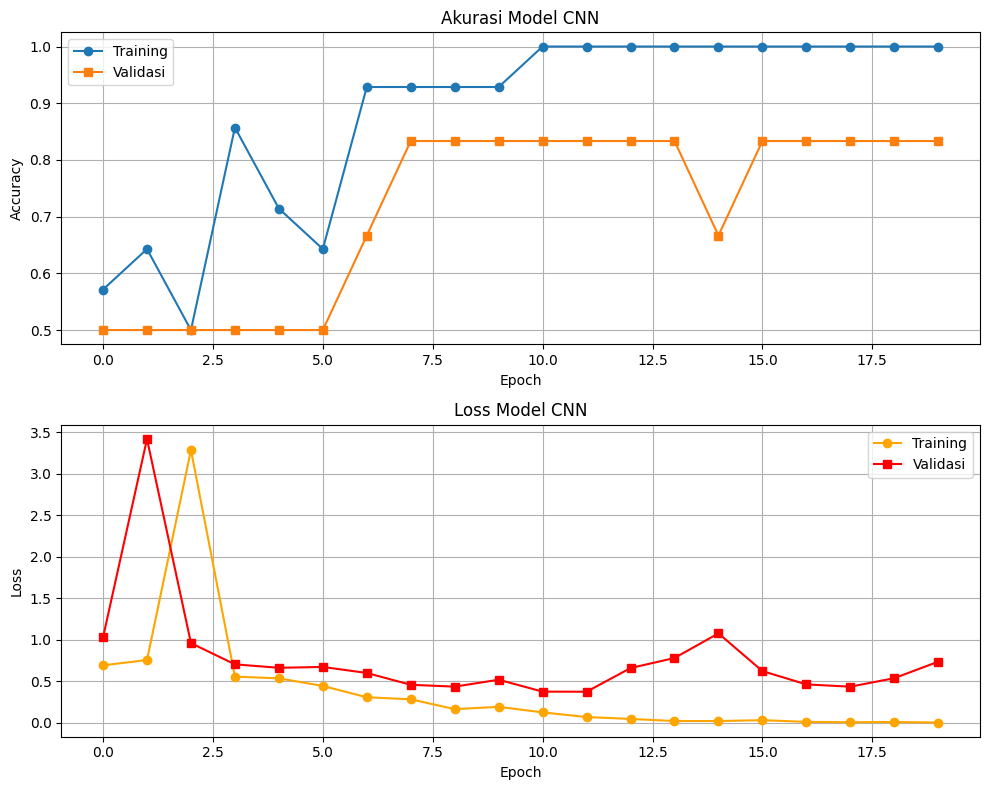

In [5]:
history = model.fit(
    train_data,
    validation_data=validation_data,
    epochs=EPOCHS
)

# Grafik Accuracy dan Loss
plt.figure(figsize=(10, 8))
plt.subplot(2, 1, 1)
plt.plot(history.history["accuracy"], label="Training", marker='o')
plt.plot(history.history["val_accuracy"], label="Validasi", marker='s')
plt.title("Akurasi Model CNN")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(history.history["loss"], label="Training", marker='o', color='orange')
plt.plot(history.history["val_loss"], label="Validasi", marker='s', color='red')
plt.title("Loss Model CNN")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Langkah 5: Evaluasi Model, Confusion Matrix, dan Classification Report
Melakukan pengujian pada data validasi secara komprehensif untuk mengukur Precision, Recall, dan F1-Score serta menyimpan model berformat `.keras`.

In [6]:
loss, accuracy = model.evaluate(validation_data)
print("====================================")
print("HASIL VALIDASI")
print("====================================")
print("Validation Loss     :", round(loss, 4))
print("Validation Accuracy :", round(accuracy * 100, 2), "%")

validation_data.reset()
hasil = model.predict(validation_data)
y_pred = (hasil >= 0.5).astype(int).reshape(-1)
y_true = validation_data.classes

cm = confusion_matrix(y_true, y_pred)
print("\n====================================")
print("CONFUSION MATRIX")
print("====================================")
print(cm)

nama_kelas = list(validation_data.class_indices.keys())
print("\n====================================")
print("CLASSIFICATION REPORT")
print("====================================")
print(classification_report(y_true, y_pred, target_names=nama_kelas))

model.save("model_motor_mobil.keras")
print("[INFO] Model berhasil disimpan ke 'model_motor_mobil.keras'")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.8333 - loss: 0.7346

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.8333 - loss: 0.7346


HASIL VALIDASI
Validation Loss     : 0.7346
Validation Accuracy : 83.33 %
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step



CONFUSION MATRIX
[[3 0]
 [1 2]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

       Mobil       0.75      1.00      0.86         3
       Motor       1.00      0.67      0.80         3

    accuracy                           0.83         6
   macro avg       0.88      0.83      0.83         6
weighted avg       0.88      0.83      0.83         6



[INFO] Model berhasil disimpan ke 'model_motor_mobil.keras'
